<a href="https://colab.research.google.com/github/milaazizah/AnalisisProject_Tahap3_Kelompok02_3TIB/blob/main/UTS_Probabilitas_dan_Statistika_Kelompok_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Mengimpor library (alat ukur dan alat gambar) yang dibutuhkan
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Membaca file excel data gempa
df = pd.read_excel('/content/Gabungan_Data_Gempa_BMKG_Untuk_Forecasting_1998-2025.xlsx')

# 3. Menampilkan 5 baris pertama untuk memastikan data sukses terbaca
print("=== 5 Baris Pertama Data ===")
display(df.head())

=== 5 Baris Pertama Data ===


,Tanggal_UTC,Waktu_UTC,Datetime_UTC,Tahun_UTC,Bulan_UTC,Lintang,Bujur,Magnitudo,Tipe_Magnitudo,Kedalaman_km
0,1998-01-09,09:45:43,1998-01-09 09:45:43,1998,1,-5.39,126.17,4.1,-,390.0
1,1998-01-12,08:05:50,1998-01-12 08:05:50,1998,1,-3.04,128.36,4.4,-,100.0
2,1998-01-18,12:03:17,1998-01-18 12:03:17,1998,1,-2.65,132.13,4.8,-,32.0
3,1998-01-29,15:05:24,1998-01-29 15:05:24,1998,1,6.76,127.28,3.8,mb,33.0
4,1998-02-05,06:15:24,1998-02-05 06:15:24,1998,2,6.88,127.22,4.3,mb,33.0


In [3]:
# Menghitung kuartil dan IQR untuk Magnitudo
q1_mag = df['Magnitudo'].quantile(0.25)
q3_mag = df['Magnitudo'].quantile(0.75)
iqr_mag = q3_mag - q1_mag

print("=== STATISTIKA DESKRIPTIF MAGNITUDO (MW) ===")
print("Rata-rata (Mean)    :", df['Magnitudo'].mean())
print("Nilai Tengah (Median):", df['Magnitudo'].median())
print("Nilai Sering Muncul :", df['Magnitudo'].mode()[0])
print("Nilai Minimum       :", df['Magnitudo'].min())
print("Nilai Maksimum      :", df['Magnitudo'].max())
print("Rentang (Range)     :", df['Magnitudo'].max() - df['Magnitudo'].min())
print("Kuartil 1 (Q1)      :", q1_mag)
print("Kuartil 3 (Q3)      :", q3_mag)
print("Interquartile (IQR) :", iqr_mag)
print("Standar Deviasi     :", df['Magnitudo'].std())
print("Varians             :", df['Magnitudo'].var())
print("Standard Error      :", df['Magnitudo'].sem())
print("Skewness            :", df['Magnitudo'].skew())
print("Kurtosis            :", df['Magnitudo'].kurtosis())

# Menghitung kuartil dan IQR untuk Depth
q1_depth = df['Kedalaman_km'].quantile(0.25)
q3_depth = df['Kedalaman_km'].quantile(0.75)
iqr_depth = q3_depth - q1_depth

print("\n=== STATISTIKA DESKRIPTIF Kedalaman_km ===")
print("Rata-rata (Mean)    :", df['Kedalaman_km'].mean())
print("Nilai Tengah (Median):", df['Kedalaman_km'].median())
print("Nilai Sering Muncul :", df['Kedalaman_km'].mode()[0])
print("Nilai Minimum       :", df['Kedalaman_km'].min())
print("Nilai Maksimum      :", df['Kedalaman_km'].max())
print("Rentang (Range)     :", df['Kedalaman_km'].max() - df['Kedalaman_km'].min())
print("Kuartil 1 (Q1)      :", q1_depth)
print("Kuartil 3 (Q3)      :", q3_depth)
print("Interquartile (IQR) :", iqr_depth)
print("Standar Deviasi     :", df['Kedalaman_km'].std())
print("Varians             :", df['Kedalaman_km'].var())
print("Standard Error      :", df['Kedalaman_km'].sem())
print("Skewness            :", df['Kedalaman_km'].skew())
print("Kurtosis            :", df['Kedalaman_km'].kurtosis())

=== STATISTIKA DESKRIPTIF MAGNITUDO (MW) ===
Rata-rata (Mean)    : 3.1573013142503266
Nilai Tengah (Median): 3.0
Nilai Sering Muncul : 2.8
Nilai Minimum       : 0.2
Nilai Maksimum      : 9.0
Rentang (Range)     : 8.8
Kuartil 1 (Q1)      : 2.5
Kuartil 3 (Q3)      : 3.7
Interquartile (IQR) : 1.2000000000000002
Standar Deviasi     : 0.862015998469699
Varians             : 0.7430715816177121
Standard Error      : 0.001846256595690897
Skewness            : 0.5015048114868383
Kurtosis            : 0.07447826178424499

=== STATISTIKA DESKRIPTIF Kedalaman_km ===
Rata-rata (Mean)    : 43.24388802495471
Nilai Tengah (Median): 14.0
Nilai Sering Muncul : 10.0
Nilai Minimum       : 1.0
Nilai Maksimum      : 798.0
Rentang (Range)     : 797.0
Kuartil 1 (Q1)      : 10.0
Kuartil 3 (Q3)      : 39.0
Interquartile (IQR) : 29.0
Standar Deviasi     : 74.96626756654697
Varians             : 5619.941272859113
Standard Error      : 0.16056194571200447
Skewness            : 4.621492275248844
Kurtosis           

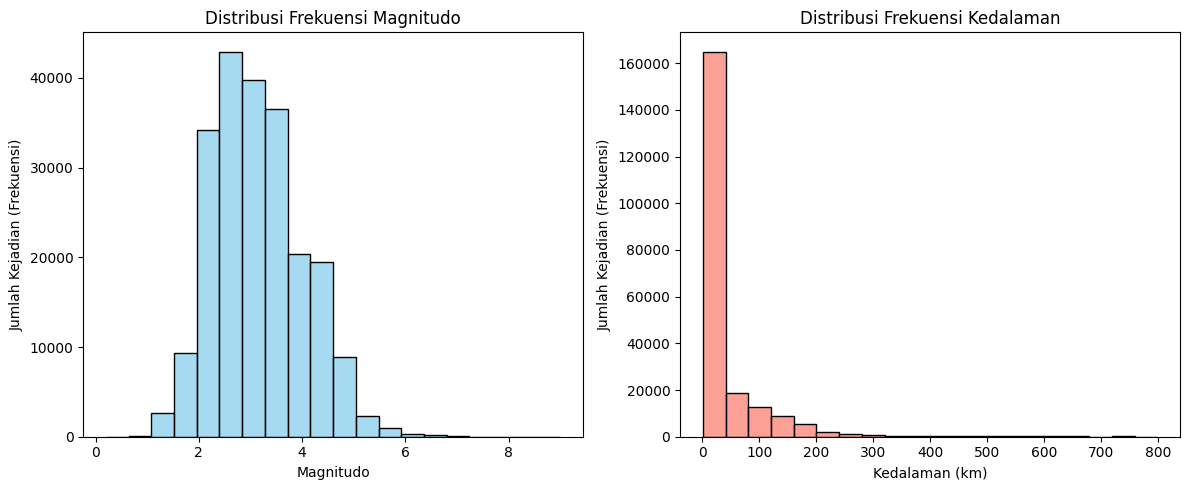

In [5]:
# Membuat 2 gambar berdampingan untuk Histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gambar 1: Histogram Magnitudo
sns.histplot(df['Magnitudo'], bins=20, color='skyblue', ax=axes[0])
axes[0].set_title('Distribusi Frekuensi Magnitudo')
axes[0].set_xlabel('Magnitudo')
axes[0].set_ylabel('Jumlah Kejadian (Frekuensi)')

# Gambar 2: Histogram Kedalaman
sns.histplot(df['Kedalaman_km'], bins=20, color='salmon', ax=axes[1])
axes[1].set_title('Distribusi Frekuensi Kedalaman')
axes[1].set_xlabel('Kedalaman (km)')
axes[1].set_ylabel('Jumlah Kejadian (Frekuensi)')

# Menampilkan gambar dengan rapi
plt.tight_layout()
plt.show()

                      Jumlah  Persen
Kategori Kedalaman                  
Dangkal (<70 km)      179732   82.45
Menengah (70-300 km)   35077   16.09
Dalam (>300 km)         3186    1.46 

                    Jumlah  Persen
Kategori Magnitudo                
3,0-<4,0            176329   80.89
4,0-<5,0             36727   16.85
5,0-<6,0              4397    2.02
>=6,0                  542    0.25 



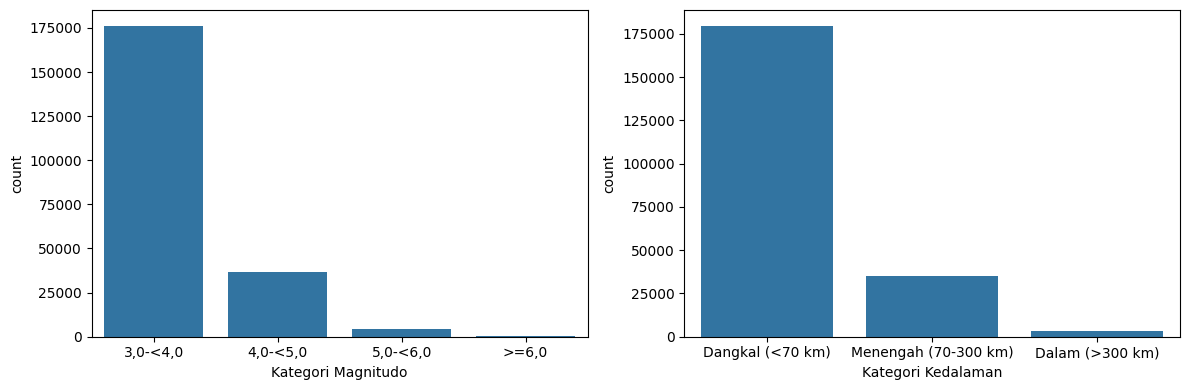

Kategori Magnitudo    3,0-<4,0  4,0-<5,0  5,0-<6,0  >=6,0
Kategori Kedalaman                                       
Dangkal (<70 km)        152238     24081      3007    406
Menengah (70-300 km)     23298     10506      1173    100
Dalam (>300 km)            793      2140       217     36


In [6]:
df['Kategori Kedalaman'] = pd.cut(df['Kedalaman_km'], [0, 70, 300, float('inf')],
    labels=['Dangkal (<70 km)', 'Menengah (70-300 km)', 'Dalam (>300 km)'], right=False)
df['Kategori Magnitudo'] = pd.cut(df['Magnitudo'], [0, 4, 5, 6, float('inf')],
    labels=['3,0-<4,0', '4,0-<5,0', '5,0-<6,0', '>=6,0'], right=False)

for k in ['Kategori Kedalaman', 'Kategori Magnitudo']:
    t = df[k].value_counts().sort_index()
    print(pd.DataFrame({'Jumlah': t, 'Persen': (t / len(df) * 100).round(2)}), '\n')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='Kategori Magnitudo', data=df, ax=axes[0])
sns.countplot(x='Kategori Kedalaman', data=df, ax=axes[1])
plt.tight_layout(); plt.show()

print(pd.crosstab(df['Kategori Kedalaman'], df['Kategori Magnitudo']))

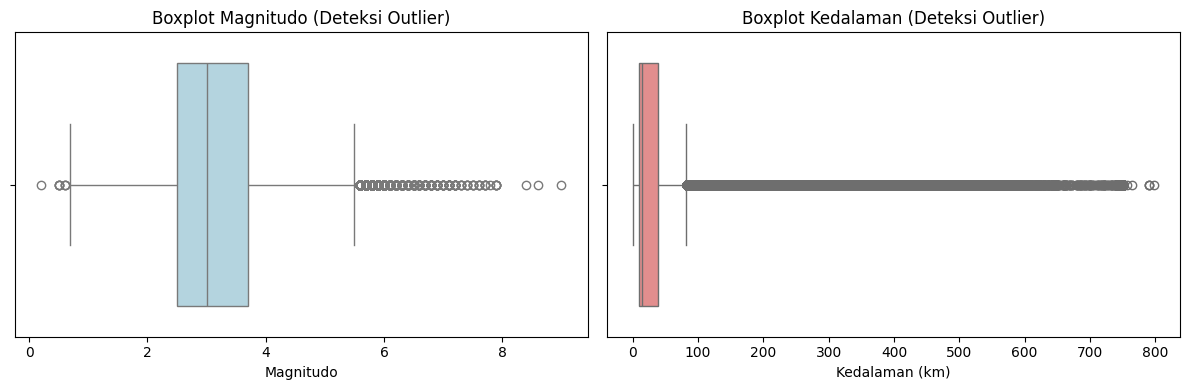

In [8]:
# Membuat 2 gambar berdampingan untuk Boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gambar 1: Boxplot Magnitudo
sns.boxplot(x=df['Magnitudo'], color='lightblue', ax=axes[0])
axes[0].set_title('Boxplot Magnitudo (Deteksi Outlier)')
axes[0].set_xlabel('Magnitudo')

# Gambar 2: Boxplot Kedalaman
sns.boxplot(x=df['Kedalaman_km'], color='lightcoral', ax=axes[1])
axes[1].set_title('Boxplot Kedalaman (Deteksi Outlier)')
axes[1].set_xlabel('Kedalaman (km)')

plt.tight_layout()
plt.show()

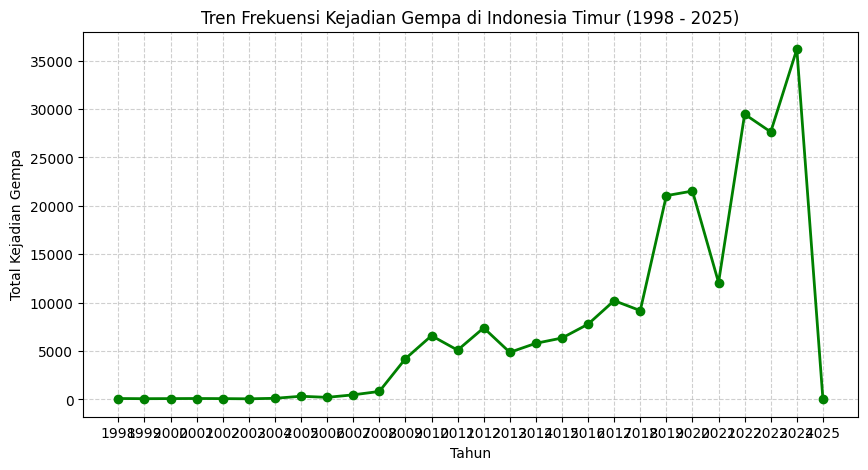

In [11]:
# Menghitung jumlah gempa berdasarkan tahun kejadian
jumlah_per_tahun = df['Tahun_UTC'].value_counts().sort_index()

# Membuat grafik garis (Time-Series Plot)
plt.figure(figsize=(10, 5))
plt.plot(jumlah_per_tahun.index, jumlah_per_tahun.values, marker='o', color='green', linewidth=2)

# Memberi judul dan label
plt.title('Tren Frekuensi Kejadian Gempa di Indonesia Timur (1998 - 2025)')
plt.xlabel('Tahun')
plt.ylabel('Total Kejadian Gempa')

# Menambahkan grid (garis bantu kotak-kotak) agar mudah dibaca
plt.grid(True, linestyle='--', alpha=0.6)

# Memastikan angka tahun di bawah (sumbu X) tidak berantakan
plt.xticks(jumlah_per_tahun.index)

plt.show()